# Incident Response Agent — Stage 1 Prototype
**Goal of this notebook:** prove the core loop works before building any UI.

```
Kaggle incident dataset  →  memory documents  →  LLM reasoning (no memory)  →  LLM reasoning (with memory) → compare
```

If the "with memory" output is visibly more specific and evidence-backed than the "no memory" output, Stage 1 is done and you're ready to move to Hindsight + Streamlit UI.

**Dataset used:** *Incident Response Log* (ServiceNow-derived event log — 141,712 events / 24,918 incidents / 36 attributes), available on Kaggle as `vipulshinde/incident-response-log` and mirrored on the UCI ML Repository as *"Incident management process enriched event log"* (id 498). This notebook gives you two ways to load it — pick whichever works faster for you.


## Step 0 — Install packages

In [ ]:
!pip install -q groq sentence-transformers scikit-learn pandas ucimlrepo kaggle


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 3.0 MB/s eta 0:00:00


## Step 1 — Load the dataset

Pick **Option A** (Kaggle) or **Option B** (UCI mirror, no login needed — easiest to get running fast). Run only the option you choose.


### Option A — Load from Kaggle
1. Go to https://www.kaggle.com/settings/account → "Create New Token" → downloads `kaggle.json`
2. Run the cell below, upload `kaggle.json` when prompted


In [ ]:
from google.colab import files
import os

uploaded = files.upload()  # upload your kaggle.json here
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!kaggle datasets download -d vipulshinde/incident-response-log -p /content/data --unzip
!ls /content/data


Saving archive (2).zip to archive (2).zip
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vipulshinde/incident-response-log
License(s): CC0-1.0
100% 2.07M/2.07M [00:00<00:00, 118MB/s]

incident_event_log.csv	Incident_response.txt


In [ ]:
import pandas as pd

df = pd.read_csv('/content/data/incident_event_log.csv')
print(df.shape)
df.head()

(119998, 36)


,number,incident_state,active,reassignment_count,reopen_count,sys_mod_count,made_sla,caller_id,opened_by,opened_at,...,u_priority_confirmation,notify,problem_id,rfc,vendor,caused_by,closed_code,resolved_by,resolved_at,closed_at
0,INC0000045,New,True,0,0,0,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,0,0,2,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,0,0,3,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,0,0,4,True,Caller 2403,Opened by 8,29/2/2016 01:16,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 149,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,0,0,0,True,Caller 2403,Opened by 397,29/2/2016 04:40,...,False,Do Not Notify,?,?,?,?,code 5,Resolved by 81,1/3/2016 09:52,6/3/2016 10:00


## Step 2 — Inspect the dataset (just enough to understand it, no deep EDA)

In [ ]:
print("Columns:", list(df.columns))
print()
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))
print()
# Look at the fields we actually care about for incident memory
candidate_cols = [c for c in df.columns if c.lower() in
    ['number','category','subcategory','priority','impact','urgency',
     'assignment_group','short_description','description',
     'close_code','resolved_at','opened_at','closed_at','incident_state','active']]
print("Fields useful for memory documents:", candidate_cols)
df[candidate_cols].head(10) if candidate_cols else df.head(10)


Columns: ['number', 'incident_state', 'active', 'reassignment_count', 'reopen_count', 'sys_mod_count', 'made_sla', 'caller_id', 'opened_by', 'opened_at', 'sys_created_by', 'sys_created_at', 'sys_updated_by', 'sys_updated_at', 'contact_type', 'location', 'category', 'subcategory', 'u_symptom', 'cmdb_ci', 'impact', 'urgency', 'priority', 'assignment_group', 'assigned_to', 'knowledge', 'u_priority_confirmation', 'notify', 'problem_id', 'rfc', 'vendor', 'caused_by', 'closed_code', 'resolved_by', 'resolved_at', 'closed_at']

Missing values per column:
number                0
incident_state        0
active                0
reassignment_count    0
reopen_count          0
sys_mod_count         0
made_sla              0
caller_id             0
opened_by             0
opened_at             0
sys_created_by        0
sys_created_at        0
sys_updated_by        0
sys_updated_at        0
contact_type          0
dtype: int64

Fields useful for memory documents: ['number', 'incident_state', 'active'

,number,incident_state,active,opened_at,category,subcategory,impact,urgency,priority,assignment_group,resolved_at,closed_at
0,INC0000045,New,True,29/2/2016 01:16,Category 55,Subcategory 170,2 - Medium,2 - Medium,3 - Moderate,Group 56,29/2/2016 11:29,5/3/2016 12:00
1,INC0000045,Resolved,True,29/2/2016 01:16,Category 55,Subcategory 170,2 - Medium,2 - Medium,3 - Moderate,Group 56,29/2/2016 11:29,5/3/2016 12:00
2,INC0000045,Resolved,True,29/2/2016 01:16,Category 55,Subcategory 170,2 - Medium,2 - Medium,3 - Moderate,Group 56,29/2/2016 11:29,5/3/2016 12:00
3,INC0000045,Closed,False,29/2/2016 01:16,Category 55,Subcategory 170,2 - Medium,2 - Medium,3 - Moderate,Group 56,29/2/2016 11:29,5/3/2016 12:00
4,INC0000047,New,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 70,1/3/2016 09:52,6/3/2016 10:00
5,INC0000047,Active,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 24,1/3/2016 09:52,6/3/2016 10:00
6,INC0000047,Active,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 24,1/3/2016 09:52,6/3/2016 10:00
7,INC0000047,Active,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 24,1/3/2016 09:52,6/3/2016 10:00
8,INC0000047,Active,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 24,1/3/2016 09:52,6/3/2016 10:00
9,INC0000047,Active,True,29/2/2016 04:40,Category 40,Subcategory 215,2 - Medium,2 - Medium,3 - Moderate,Group 24,1/3/2016 09:52,6/3/2016 10:00


## Step 3 — Transform rows into "memory documents"

Don't dump the raw dataframe into the LLM. Turn each incident into a short structured
text block — this is what becomes your agent's memory. We take a small curated sample
(30–50 unique incidents), not all 141K rows.


In [ ]:
memory_documents = [
"""Incident ID: INC1001
Category: Application / API
Symptom: Production API returning 503 errors, ~70% of requests failing after a deployment
Affected System: payment-api-service
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: New deployment introduced a memory leak in the connection handler
Resolution: Rolled back to previous deployment version
Resolution Time: 25 minutes
Outcome: Resolved""",

"""Incident ID: INC1002
Category: Database
Symptom: Checkout service timing out, database connection pool exhausted
Affected System: orders-db
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Connection leak in payment service not releasing connections after retries
Resolution: Increased connection pool size and patched retry logic
Resolution Time: 42 minutes
Outcome: Resolved""",

"""Incident ID: INC1003
Category: Network
Symptom: VPN connectivity failures reported by multiple remote users
Affected System: corporate-vpn-gateway
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: VPN gateway certificate expired
Resolution: Renewed certificate and restarted gateway service
Resolution Time: 18 minutes
Outcome: Resolved""",

"""Incident ID: INC1004
Category: Authentication
Symptom: Users unable to log in, SSO login page returning 500 error
Affected System: auth-service
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Identity provider (IdP) integration token expired
Resolution: Refreshed IdP integration credentials and redeployed auth service
Resolution Time: 15 minutes
Outcome: Resolved""",

"""Incident ID: INC1005
Category: Infrastructure
Symptom: Application servers unresponsive, high CPU usage across all instances
Affected System: web-frontend-cluster
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Infinite loop introduced by a recent code change in the request handler
Resolution: Hotfix deployed to remove the faulty loop, cluster restarted
Resolution Time: 33 minutes
Outcome: Resolved""",

"""Incident ID: INC1006
Category: Storage
Symptom: File upload failures, application logs show disk write errors
Affected System: file-storage-node-3
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: Disk partition reached 100% capacity due to unrotated logs
Resolution: Cleared old log files and enabled log rotation policy
Resolution Time: 20 minutes
Outcome: Resolved""",

"""Incident ID: INC1007
Category: Deployment
Symptom: New release causing intermittent 500 errors on the checkout page
Affected System: checkout-service
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Missing environment variable in new deployment config
Resolution: Added missing config value and redeployed
Resolution Time: 12 minutes
Outcome: Resolved""",

"""Incident ID: INC1008
Category: Email / Messaging
Symptom: Outbound transactional emails (password resets, receipts) not being delivered
Affected System: email-notification-service
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Third-party email provider API key expired
Resolution: Rotated API key and verified delivery with test emails
Resolution Time: 22 minutes
Outcome: Resolved""",

"""Incident ID: INC1009
Category: Load Balancer
Symptom: Random 502 Bad Gateway errors for a subset of users
Affected System: main-load-balancer
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: Health check misconfiguration marking healthy nodes as down
Resolution: Corrected health check timeout threshold
Resolution Time: 16 minutes
Outcome: Resolved""",

"""Incident ID: INC1010
Category: Cache
Symptom: Slow page load times across the site, cache hit rate near zero
Affected System: redis-cache-cluster
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Cache cluster failover event caused cold cache
Resolution: Warmed cache manually and adjusted failover alerting
Resolution Time: 28 minutes
Outcome: Resolved""",

"""Incident ID: INC1011
Category: DNS
Symptom: Users intermittently unable to reach the website, "server not found" errors
Affected System: dns-provider
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: DNS record TTL misconfiguration during a DNS provider migration
Resolution: Reverted DNS records and extended TTL settings
Resolution Time: 40 minutes
Outcome: Resolved""",

"""Incident ID: INC1012
Category: Database
Symptom: Read replica lag causing stale data on dashboard reports
Affected System: analytics-db-replica
Priority: 3 - Moderate | Impact: Low | Urgency: Medium
Root Cause: Large batch write job overloaded replication process
Resolution: Throttled batch job and increased replica resources
Resolution Time: 55 minutes
Outcome: Resolved""",

"""Incident ID: INC1013
Category: Application / API
Symptom: API returning 429 Too Many Requests errors for legitimate traffic
Affected System: public-api-gateway
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Rate limit threshold set too low after a config change
Resolution: Adjusted rate limit thresholds back to previous values
Resolution Time: 10 minutes
Outcome: Resolved""",

"""Incident ID: INC1014
Category: Security
Symptom: Multiple failed login attempts triggering account lockouts for real users
Affected System: auth-service
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: Automated bot traffic triggering brute-force protection false positives
Resolution: Added bot detection rule and whitelisted affected user IPs
Resolution Time: 30 minutes
Outcome: Resolved""",

"""Incident ID: INC1015
Category: Infrastructure
Symptom: Background job queue backed up, scheduled tasks not running
Affected System: job-worker-cluster
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Worker pods crash-looping due to out-of-memory errors
Resolution: Increased memory limits and fixed memory leak in job processor
Resolution Time: 45 minutes
Outcome: Resolved""",

"""Incident ID: INC1016
Category: Third-Party Integration
Symptom: Payment processing failing for all card transactions
Affected System: payment-gateway-integration
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Third-party payment provider had an outage on their end
Resolution: Failed over to backup payment provider, monitored until primary recovered
Resolution Time: 50 minutes
Outcome: Resolved""",

"""Incident ID: INC1017
Category: Database
Symptom: Application errors referencing "too many connections" to the database
Affected System: primary-app-db
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Connection pool exhaustion from a runaway reporting query
Resolution: Killed the runaway query and added query timeout limits
Resolution Time: 20 minutes
Outcome: Resolved""",

"""Incident ID: INC1018
Category: Deployment
Symptom: Mobile app crashing on launch after latest backend API update
Affected System: mobile-backend-api
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Backend API removed a field the mobile app still depended on
Resolution: Restored backward-compatible field and coordinated versioned rollout
Resolution Time: 35 minutes
Outcome: Resolved""",

"""Incident ID: INC1019
Category: Monitoring / Alerting
Symptom: No alerts fired despite a 2-hour service outage overnight
Affected System: monitoring-stack
Priority: 3 - Moderate | Impact: Medium | Urgency: Low
Root Cause: Alerting service lost connection to its notification channel
Resolution: Restored notification channel integration and added a heartbeat check
Resolution Time: 60 minutes
Outcome: Resolved""",

"""Incident ID: INC1020
Category: Application / API
Symptom: Search functionality returning empty results for all queries
Affected System: search-indexing-service
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Search index corrupted during a scheduled reindex job
Resolution: Restored index from last known good snapshot and re-ran indexing
Resolution Time: 38 minutes
Outcome: Resolved""",
]

print(f"Built {len(memory_documents)} memory documents.\n")
print(memory_documents[0])

Built 20 memory documents.

Incident ID: INC1001
Category: Application / API
Symptom: Production API returning 503 errors, ~70% of requests failing after a deployment
Affected System: payment-api-service
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: New deployment introduced a memory leak in the connection handler
Resolution: Rolled back to previous deployment version
Resolution Time: 25 minutes
Outcome: Resolved


## Step 4 — Bare LLM reasoning agent (no memory yet)

This proves the reasoning half of the loop works on its own. Get a free Groq API key at
https://console.groq.com/keys and paste it below.


In [ ]:
from getpass import getpass
import os

os.environ["GROQ_API_KEY"] = getpass("Paste your Groq API key: ")


Paste your Groq API key: ··········


### Patch cell (added): define `test_incident`
The original Step 4 cell uses `test_incident`, but no cell in the original notebook defines it, so a fresh Run-All stops with a NameError. This one added cell defines it (reconstructed from the incident shown in the original outputs). No original cell was edited.

In [ ]:
test_incident = ("Production API is returning 503 Service Unavailable errors for roughly 60% of requests, "
                 "started about 10 minutes ago.")

In [ ]:
from groq import Groq

client = Groq(api_key=os.environ["GROQ_API_KEY"])
MODEL = "openai/gpt-oss-120b"   # or "qwen/qwen3-32b"

DIAGNOSIS_PROMPT = """You are an IT Incident Response Agent. Given the incident description below,
produce a structured diagnosis.

Incident description:
{incident}

{context_block}

Important: Only reference a past incident in "Similar Past Incidents" if it is GENUINELY similar
in symptom, affected system, or root cause to the current incident. If the context contains no
closely related incidents, say "No closely related past incidents found" — do not force a weak
or unrelated match just because context was provided.

Respond in this exact structure:

Summary: <one line>
Category: <e.g. Network / Application / Database / Infrastructure>
Severity: <Low / Medium / High / Critical>
Likely Root Causes:
- <cause 1>
- <cause 2>
Similar Past Incidents: <describe genuinely matching past incident(s) using whatever identifying
details are available — incident ID if present, otherwise affected system + date + symptom.
If no context was given, or nothing is genuinely similar, say "No closely related past incidents found">
Recommended Investigation Steps:
1. <step>
2. <step>
3. <step>
Recommended Immediate Action: <one clear next step>
Escalation: <team to escalate to, or "Not required yet">
Confidence: <low/medium/high — based on how well the evidence supports this>
"""

def diagnose(incident_text, context_block=""):
    prompt = DIAGNOSIS_PROMPT.format(incident=incident_text, context_block=context_block)
    resp = client.chat.completions.create(
        model=MODEL,
        messages=[{"role": "user", "content": prompt}],
        temperature=0.1,
    )
    return resp.choices[0].message.content

# Re-test baseline
print("=== DIAGNOSIS WITHOUT MEMORY ===\n")
no_memory_result = diagnose(test_incident)
print(no_memory_result)

=== DIAGNOSIS WITHOUT MEMORY ===

**Summary:** Production API is returning 503 Service Unavailable for ~60 % of requests, began ~10 minutes ago.  

**Category:** Application / Infrastructure (API layer & load‑balancing)  

**Severity:** High  

**Likely Root Causes:**  
- Upstream service or database latency/time‑outs causing the API to fail health checks.  
- Load balancer or reverse‑proxy (e.g., NGINX, Envoy, ALB) mis‑routing or marking instances unhealthy.  
- Resource exhaustion on API servers (CPU, memory, thread pool, connection pool).  
- Recent deployment/config change introducing a bug or breaking dependency.  

**Similar Past Incidents:** No closely related past incidents found  

**Recommended Investigation Steps:**  
1. **Check health‑check status** on the load balancer / service mesh – identify which instances are marked unhealthy and why.  
2. **Inspect recent logs** (API server, load balancer, upstream services) for error spikes, time‑outs, or circuit‑breaker events arou

## Step 5 — Add retrieval (this is what makes it "memory", not a chatbot)

Embed the memory documents once, embed the new incident the same way, and pull the
top 3 most similar past incidents as context for the LLM.


In [ ]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

embedder = SentenceTransformer('all-MiniLM-L6-v2')

memory_embeddings = embedder.encode(memory_documents)

def find_similar(incident_text, top_k=3):
    query_embedding = embedder.encode([incident_text])
    sims = cosine_similarity(query_embedding, memory_embeddings)[0]
    top_indices = np.argsort(sims)[::-1][:top_k]
    return [(memory_documents[i], float(sims[i])) for i in top_indices]

similar = find_similar(test_incident)
print("Top similar past incidents:\n")
for doc, score in similar:
    print(f"[similarity: {score:.2f}]")
    print(doc)
    print("---")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Top similar past incidents:

[similarity: 0.69]
Incident ID: INC1001
Category: Application / API
Symptom: Production API returning 503 errors, ~70% of requests failing after a deployment
Affected System: payment-api-service
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: New deployment introduced a memory leak in the connection handler
Resolution: Rolled back to previous deployment version
Resolution Time: 25 minutes
Outcome: Resolved
---
[similarity: 0.55]
Incident ID: INC1013
Category: Application / API
Symptom: API returning 429 Too Many Requests errors for legitimate traffic
Affected System: public-api-gateway
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Rate limit threshold set too low after a config change
Resolution: Adjusted rate limit thresholds back to previous values
Resolution Time: 10 minutes
Outcome: Resolved
---
[similarity: 0.47]
Incident ID: INC1007
Category: Deployment
Symptom: New release causing intermittent 500 errors on the c

## Step 6 — Memory-augmented diagnosis

In [ ]:
def diagnose_with_memory(incident_text, top_k=3):
    similar_incidents = find_similar(incident_text, top_k=top_k)
    context_lines = ["Relevant past incidents from memory:\n"]
    for doc, score in similar_incidents:
        context_lines.append(doc)
        context_lines.append("")
    context_block = "\n".join(context_lines)
    return diagnose(incident_text, context_block=context_block)

print("=== DIAGNOSIS WITH MEMORY ===\n")
with_memory_result = diagnose_with_memory(test_incident)
print(with_memory_result)


=== DIAGNOSIS WITH MEMORY ===

**Summary:** Production API is returning 503 Service Unavailable for ~60% of requests, onset ~10 minutes ago.  

**Category:** Application / API  

**Severity:** High  

**Likely Root Causes:**  
- Recent code or configuration deployment introducing a bug (e.g., memory leak, thread pool exhaustion).  
- Resource exhaustion on the API host (CPU, memory, file descriptors, DB connection pool).  
- Failure of a critical upstream dependency (e.g., database, external service) causing the API to reject traffic.  
- Load‑balancer or reverse‑proxy misconfiguration (e.g., health‑check failures, timeout settings).  

**Similar Past Incidents:**  
- **INC1001** – Production API (payment‑api‑service) returned 503 errors (~70% failure) immediately after a deployment; root cause was a memory leak in the connection handler. The symptom (503 surge) and trigger (recent deployment) closely match the current situation.  

**Recommended Investigation Steps:**  
1. **Check rec

## Step 7 — Side-by-side comparison (Stage 1 success check)

If the "with memory" version references specific past incident IDs and gives more
grounded reasoning than the "no memory" version, your core loop works — Stage 1 is complete.


In [ ]:
print("#"*70)
print("NO MEMORY")
print("#"*70)
print(no_memory_result)
print()
print("#"*70)
print("WITH MEMORY")
print("#"*70)
print(with_memory_result)


######################################################################
NO MEMORY
######################################################################
**Summary:** Production API is returning 503 Service Unavailable for ~60 % of requests, began ~10 minutes ago.  

**Category:** Application / Infrastructure (API layer & load‑balancing)  

**Severity:** High  

**Likely Root Causes:**  
- Upstream service or database latency/time‑outs causing the API to fail health checks.  
- Load balancer or reverse‑proxy (e.g., NGINX, Envoy, ALB) mis‑routing or marking instances unhealthy.  
- Resource exhaustion on API servers (CPU, memory, thread pool, connection pool).  
- Recent deployment/config change introducing a bug or breaking dependency.  

**Similar Past Incidents:** No closely related past incidents found  

**Recommended Investigation Steps:**  
1. **Check health‑check status** on the load balancer / service mesh – identify which instances are marked unhealthy and why.  
2. **Inspect re

## Next steps (Stage 2 — not in this notebook)
- Replace the manual `find_similar` similarity search with real Hindsight `recall`
- Add a `retain` step after each resolved incident so memory grows over time
- Wrap this loop in a Streamlit UI with an "Agent Memory" panel showing retrieved incidents
- Add the post-mortem → retain loop so the agent demonstrably learns


## Step 8 — Connect to Hindsight

Replace the manual embedding-based retrieval with real Hindsight retain/recall.
Get your API key from ui.hindsight.vectorize.io → Connect → Create API Key.

In [ ]:
!pip install -q nest_asyncio
import nest_asyncio
nest_asyncio.apply()

In [ ]:
!pip install -q hindsight-client

from getpass import getpass
from hindsight_client import Hindsight

hindsight_api_key = getpass("Paste your Hindsight API key: ")

hs_client = Hindsight(
    base_url="https://api.hindsight.vectorize.io",
    api_key=hindsight_api_key
)

BANK_ID = "incident-response-demo"
print("Connected to Hindsight.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 422.7/422.7 kB 10.2 MB/s eta 0:00:00
Paste your Hindsight API key: ··········
Connected to Hindsight.


## Step 9 — Retain the curated incidents into Hindsight

This pushes your 20 memory documents into a real Hindsight memory bank.

In [ ]:
for doc in memory_documents:
    hs_client.retain(bank_id=BANK_ID, content=doc)

print(f"Retained {len(memory_documents)} incidents into Hindsight bank '{BANK_ID}'.")

Retained 20 incidents into Hindsight bank 'incident-response-demo'.


## Step 10 — Recall via Hindsight (replaces manual find_similar)

In [ ]:
def find_similar_hindsight(incident_text, top_k=3, max_tokens=1000):
    result = hs_client.recall(
        bank_id=BANK_ID,
        query=incident_text,
        max_tokens=max_tokens
    )
    # result.results may return more than you want to display — trim to top_k here
    return [(m.text, getattr(m, 'score', None)) for m in result.results[:top_k]]

In [ ]:
hindsight_matches = find_similar_hindsight(test_incident)

print("Top similar past incidents (via Hindsight recall):\n")
for doc, score in hindsight_matches:
    print(f"[score: {score}]" if score is not None else "[no score attribute]")
    print(doc)
    print("---")

Top similar past incidents (via Hindsight recall):

[no score attribute]
Incident INC1001 occurred on 2026-09-27 and 2026-09-28, involving 503 errors on the payment-api-service affecting 70% of requests due to a memory leak in the connection handler introduced by a deployment; it was resolved by rolling back to the previous version.
---
[no score attribute]
Production API payment-api-service experienced 503 errors affecting 70% of requests following a deployment. | When: 2026-09-28 | Memory leak in the connection handler introduced by new deployment.
---
[no score attribute]
Production API payment-api-service experienced 503 errors affecting 70% of requests following a deployment. | When: 2026-09-28 | New deployment introduced a memory leak in the connection handler.
---


## Step 11 — Memory-augmented diagnosis using Hindsight recall

In [ ]:
def diagnose_with_hindsight(incident_text, top_k=3):
    matches = find_similar_hindsight(incident_text, top_k=top_k)
    context_lines = ["Relevant past incidents from memory:\n"]
    for doc, score in matches:
        context_lines.append(doc)
        context_lines.append("")
    context_block = "\n".join(context_lines)
    return diagnose(incident_text, context_block=context_block)

print("=== DIAGNOSIS WITH HINDSIGHT MEMORY ===\n")
hindsight_result = diagnose_with_hindsight(test_incident)
print(hindsight_result)

=== DIAGNOSIS WITH HINDSIGHT MEMORY ===

**Summary:** Production API is returning 503 Service Unavailable errors for roughly 60% of requests, started ~10 minutes ago.  

**Category:** Application  

**Severity:** High  

**Likely Root Causes:**  
- Recent deployment introducing a resource leak or exhaustion (e.g., memory leak, thread‑pool exhaustion)  
- Failure or latency in a critical upstream dependency (database, external service) causing the API to become unavailable  
- Load balancer / reverse‑proxy health‑check misconfiguration marking the service unhealthy  

**Similar Past Incidents:** INC1001 – 2026‑09‑28 – payment‑api‑service returned 503 errors on ~70% of requests after a deployment introduced a memory leak in the connection handler; resolved by rolling back to the previous version.  

**Recommended Investigation Steps:**  
1. Examine the deployment timeline; identify any code or configuration changes pushed in the last 30 minutes and retrieve the new version’s commit hash.

## Step 12 — Retain/learn loop (the "agent gets smarter" demo)

Simulates: incident happens → gets resolved → post-mortem saved → next similar incident recalls it.

In [ ]:
def resolve_and_learn(incident_text, root_cause, action_taken, outcome):
    postmortem = f"""Incident: {incident_text}
Root Cause: {root_cause}
Action Taken: {action_taken}
Outcome: {outcome}
Lesson: When incidents like this occur, check for {root_cause} first."""
    hs_client.retain(bank_id=BANK_ID, content=postmortem)
    print("Post-mortem retained. Future similar incidents will recall this.\n")
    print(postmortem)

In [ ]:
# Step A: a brand-new incident type not in your original 20
new_incident = "Users report that the mobile app freezes and crashes immediately after opening, started right after today's app update."

print("=== BEFORE LEARNING ===\n")
print(diagnose_with_hindsight(new_incident))

# Step B: resolve it and teach the agent
resolve_and_learn(
    incident_text=new_incident,
    root_cause="incompatible SDK version bundled in the latest app update",
    action_taken="rolled back the app update and pushed a hotfix release",
    outcome="Resolved, crash rate returned to normal within 20 minutes"
)

# Step C: a similar incident comes in later — does the agent now recall the lesson?
similar_incident = "Mobile app is crashing on startup for a large number of users after the newest release went out."

print("\n=== AFTER LEARNING (new similar incident) ===\n")
print(diagnose_with_hindsight(similar_incident))

=== BEFORE LEARNING ===

**Summary:** Mobile app freezes and crashes immediately after opening following today’s update.  
**Category:** Application  
**Severity:** High  
**Likely Root Causes:**  
- Introduction of a regression bug in the latest code (e.g., null‑pointer, infinite loop, or UI deadlock).  
- Incompatible third‑party library or SDK version bundled with the new build.  
- Misconfiguration of app manifest or signing that prevents proper initialization.  

**Similar Past Incidents:**  
- Mobile app experienced freezing and crashing immediately after opening following an app update. | When: 2026‑09‑27 | Involving: users  
- Mobile app freezes and crashes immediately after opening following an update. | When: 2026‑09‑28 | Involving: users  

**Recommended Investigation Steps:**  
1. Reproduce the issue on a test device using the latest build and capture crash logs (e.g., Crashlytics, Logcat).  
2. Compare the new build’s binary and dependency list with the previous stable ver

In [ ]:
additional_memory_documents = [
"""Incident ID: INC1021
Category: Authentication
Symptom: Two-factor authentication codes not being delivered via SMS
Affected System: sms-2fa-gateway
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: SMS provider account hit daily message quota
Resolution: Increased quota with provider and enabled backup SMS provider failover
Resolution Time: 27 minutes
Outcome: Resolved""",

"""Incident ID: INC1022
Category: Infrastructure
Symptom: Kubernetes pods repeatedly restarting (CrashLoopBackOff) in production namespace
Affected System: order-processing-cluster
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Misconfigured liveness probe timeout too aggressive after latest deploy
Resolution: Adjusted liveness probe timeout and redeployed
Resolution Time: 19 minutes
Outcome: Resolved""",

"""Incident ID: INC1023
Category: Database
Symptom: Reporting dashboard showing incorrect/stale numbers compared to source data
Affected System: analytics-warehouse
Priority: 3 - Moderate | Impact: Low | Urgency: Low
Root Cause: Nightly ETL job silently failed three days in a row without alerting
Resolution: Fixed ETL job error handling and re-ran backfill
Resolution Time: 90 minutes
Outcome: Resolved""",

"""Incident ID: INC1024
Category: Network
Symptom: Intermittent packet loss between application servers and database in one region
Affected System: us-east-network-segment
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Faulty network switch in the affected availability zone
Resolution: Failed over to healthy availability zone, replaced switch
Resolution Time: 48 minutes
Outcome: Resolved""",

"""Incident ID: INC1025
Category: Application / API
Symptom: GraphQL API returning partial/null data for nested queries intermittently
Affected System: graphql-gateway
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Downstream microservice timeout not handled gracefully in resolver
Resolution: Added timeout handling and fallback caching in resolver
Resolution Time: 33 minutes
Outcome: Resolved""",

"""Incident ID: INC1026
Category: Security
Symptom: Unusual outbound traffic spike detected from an internal server
Affected System: internal-batch-server-04
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Compromised dependency in a scheduled script pulling from a malicious package mirror
Resolution: Isolated server, rotated credentials, patched dependency source
Resolution Time: 75 minutes
Outcome: Resolved""",

"""Incident ID: INC1027
Category: Storage
Symptom: Backup jobs failing silently for the past two nights
Affected System: backup-service
Priority: 2 - High | Impact: Medium | Urgency: Medium
Root Cause: Backup storage bucket permissions changed during a security policy update
Resolution: Restored correct bucket permissions and re-ran backup manually
Resolution Time: 24 minutes
Outcome: Resolved""",

"""Incident ID: INC1028
Category: Deployment
Symptom: Feature flag rollout caused checkout errors for a subset of users
Affected System: checkout-service
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: Feature flag enabled for a user segment before dependent backend change was deployed
Resolution: Disabled feature flag, coordinated deployment order for retry
Resolution Time: 14 minutes
Outcome: Resolved""",

"""Incident ID: INC1029
Category: Third-Party Integration
Symptom: Shipping rate calculator returning errors at checkout
Affected System: shipping-rate-api-integration
Priority: 2 - High | Impact: Medium | Urgency: High
Root Cause: Third-party shipping API changed their response schema without notice
Resolution: Updated integration parser to handle new schema, added schema validation alerting
Resolution Time: 41 minutes
Outcome: Resolved""",

"""Incident ID: INC1030
Category: Infrastructure
Symptom: Autoscaling not triggering during traffic spike, requests queueing up
Affected System: web-frontend-autoscaler
Priority: 1 - Critical | Impact: High | Urgency: High
Root Cause: Autoscaling metric source misconfigured after monitoring stack migration
Resolution: Repointed autoscaler to correct metric source, manually scaled during incident
Resolution Time: 22 minutes
Outcome: Resolved""",
]

memory_documents.extend(additional_memory_documents)

for doc in additional_memory_documents:
    hs_client.retain(bank_id=BANK_ID, content=doc)

print(f"Retained {len(additional_memory_documents)} more incidents. Total memory bank size: {len(memory_documents)}")

Retained 10 more incidents. Total memory bank size: 30


In [ ]:
test_scenarios = [
    ("Auth failure", "Users getting logged out randomly and 2FA codes aren't arriving via text message."),
    ("Disk full", "Application logs stopped writing, disk usage on the file server shows 100% full."),
    ("DNS issue", "Some users can't reach our website at all, getting 'server not found' errors intermittently."),
    ("Cache failure", "Website is loading very slowly for everyone, cache hit rate dropped to almost zero."),
    ("Third-party outage", "Customers can't complete payment, card transactions are all failing."),
    ("Kubernetes crash loop", "Pods in the order processing cluster keep restarting over and over."),
    ("Totally unrelated (hallucination check)", "The office printer on the 3rd floor is out of toner and needs a refill."),
]

for label, incident_text in test_scenarios:
    print("="*80)
    print(f"SCENARIO: {label}")
    print("="*80)
    result = diagnose_with_hindsight(incident_text)
    print(result)
    print()

SCENARIO: Auth failure
**Summary:** Users are being logged out unexpectedly and are not receiving SMS‑based 2FA codes.  

**Category:** Application (authentication service)  

**Severity:** High  

**Likely Root Causes:**  
- SMS provider account has reached its daily message quota or is experiencing an outage.  
- Expired or invalid identity‑provider integration token causing authentication service failures.  
- Session store or token‑validation service malfunction leading to premature session invalidation.  

**Similar Past Incidents:**  
- **INC1021 (2026‑09‑27 / 2026‑09‑28):** SMS two‑factor codes were not delivered because the SMS provider account hit its daily quota. The issue was resolved by increasing the quota and enabling a backup provider failover.  
- **INC1004 (2026‑09‑27 / 2026‑09‑28):** Users experienced login failures due to a 500 error on the SSO login page caused by an expired identity‑provider integration token; resolved by refreshing credentials and redeploying the 

# Part 2: Improvements (added cells only)
Everything above this line is the original Stage 1 + Stage 2 notebook, unchanged. The one exception is a single added cell before Step 4 that defines `test_incident`, which the original never defines.

What is added below, and why:

| # | Improvement | Fixes |
|---|---|---|
| 1 | Validated JSON diagnosis with retries | Free-text output was hard to score and could break format |
| 2 | Real Kaggle data instead of hand-written incidents | The dataset was loaded but never used |
| 3 | Chronological baseline-vs-Hindsight evaluation | No measurable proof that memory helps |
| 4 | Hindsight `reflect` | Only `retain` and `recall` were used |
| 5 | Interactive UI (Gradio, inside this notebook) | Demo-ready front end |

In [ ]:
!pip install -q gradio matplotlib tqdm
import json, re, time
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Improvement 1: Validated JSON diagnosis
New functions (`llm_json`, `diagnose_json`); the original `diagnose` is left as is. The output is parsed, checked for required keys and retried with backoff, which also covers Groq rate limits and function-calling flakiness.

In [ ]:
DIAG_KEYS = ["summary", "category", "severity", "root_causes", "similar_incident", "cited_memory",
             "investigation_steps", "immediate_action", "escalation", "confidence"]

DIAG_PROMPT = """You are an IT Incident Response Agent.

Current incident:
<<INCIDENT>>

Relevant past incidents from memory (numbered):
<<CONTEXT>>

Rules:
- Only cite a memory if it is GENUINELY similar in symptom, system or root cause.
- If nothing is genuinely similar, set "cited_memory" to null and say so in "similar_incident".
- Never invent past incidents.

Return ONLY a JSON object, no prose, no markdown fences, with exactly these keys:
{"summary": "one line",
 "category": "Network | Application | Database | Infrastructure | Security | Other",
 "severity": "Low | Medium | High | Critical",
 "root_causes": ["...", "..."],
 "similar_incident": "what past incident matches and why, or 'No closely related past incidents found'",
 "cited_memory": 1,
 "investigation_steps": ["...", "...", "..."],
 "immediate_action": "one clear next step",
 "escalation": "team to escalate to, or 'Not required yet'",
 "confidence": "low | medium | high"}
"""

def llm_json(prompt, required, retries=3, temperature=0.1):
    last = None
    for attempt in range(retries):
        try:
            resp = client.chat.completions.create(
                model=MODEL, messages=[{"role": "user", "content": prompt}], temperature=temperature)
            raw = (resp.choices[0].message.content or "").strip()
            raw = re.sub(r"^```(?:json)?|```$", "", raw, flags=re.M).strip()
            m = re.search(r"\{.*\}", raw, re.S)
            data = json.loads(m.group(0) if m else raw)
            missing = [k for k in required if k not in data]
            if missing:
                raise ValueError(f"missing keys {missing}")
            return data
        except Exception as e:
            last = e
            time.sleep(3 * (attempt + 1))
    raise RuntimeError(f"LLM JSON call failed after {retries} attempts: {last}")

def diagnose_json(incident_text, matches):
    ctx = "\n\n".join(f"[{i + 1}] {t}" for i, (t, _) in enumerate(matches)) or "None"
    prompt = DIAG_PROMPT.replace("<<INCIDENT>>", incident_text).replace("<<CONTEXT>>", ctx)
    return llm_json(prompt, DIAG_KEYS)

sample_diag = diagnose_json(test_incident, find_similar_hindsight(test_incident))
print(json.dumps(sample_diag, indent=2))

{
  "summary": "Production API is returning 503 Service Unavailable for ~60% of requests, started 10 minutes ago",
  "category": "Application",
  "severity": "High",
  "root_causes": [
    "Recent deployment introducing a bug or resource leak",
    "Exhaustion of connection pool or thread pool",
    "Downstream service outage causing request timeouts",
    "Infrastructure scaling limits reached (CPU/memory)",
    "Load balancer misconfiguration"
  ],
  "similar_incident": "No closely related past incidents found",
  "cited_memory": null,
  "investigation_steps": [
    "Check deployment history for any releases in the last hour",
    "Review application and web server logs for error patterns or stack traces",
    "Monitor CPU, memory, and connection pool metrics on the API instances",
    "Verify health of downstream services and database connectivity",
    "Inspect load balancer and reverse proxy health checks"
  ],
  "immediate_action": "If a recent deployment exists, initiate an imme

## Improvement 2: Build the memory from the real Kaggle log
The original memory was 20 hand-written incidents. Here the event log already loaded into `df` is collapsed to one row per incident and turned into memory records.

The dataset is anonymized (values look like `Category 46`, `Group 70`), so the agent predicts two measurable things: **which assignment group finally resolves the incident** and **how long resolution takes** (fast / medium / slow terciles).

Adjust `N_SEED`, `N_TEST`, `WINDOW` to trade accuracy of the evidence against Hindsight and Groq time and credits.

In [ ]:
N_SEED, N_TEST, WINDOW, SEED_FRAC = 200, 100, 20, 0.7

NEED = ["number", "opened_at", "resolved_at", "sys_updated_at", "category", "subcategory", "priority",
        "impact", "urgency", "assignment_group", "closed_code", "reassignment_count", "reopen_count"]
missing = [c for c in NEED if c not in df.columns]
assert not missing, f"Columns not found in df: {missing}. Print df.columns and adjust NEED."

raw = df.replace("?", np.nan).copy()
if "u_symptom" not in raw:
    raw["u_symptom"] = np.nan
for c in ["opened_at", "resolved_at", "sys_updated_at"]:
    raw[c] = pd.to_datetime(raw[c], dayfirst=True, errors="coerce")
for c in ["reassignment_count", "reopen_count"]:
    raw[c] = pd.to_numeric(raw[c], errors="coerce")
raw = raw.sort_values(["number", "sys_updated_at"])

g = raw.groupby("number")
inc = g[["category", "subcategory", "u_symptom", "priority", "impact", "urgency",
         "assignment_group", "closed_code"]].last()          # last non-null value per incident
inc["opened_at"] = g["opened_at"].min()
inc["resolved_at"] = g["resolved_at"].max()
inc["reassignments"] = g["reassignment_count"].max().fillna(0)
inc["reopens"] = g["reopen_count"].max().fillna(0)
inc = inc.dropna(subset=["opened_at", "resolved_at", "assignment_group", "category"])
inc["ttr_hours"] = (inc.resolved_at - inc.opened_at).dt.total_seconds() / 3600
inc = inc[inc.ttr_hours >= 0].fillna({"subcategory": "unknown", "u_symptom": "unknown", "close_code": "unknown"})
inc = inc.sort_values("opened_at")

print(f"{len(inc):,} resolved incidents | {inc.opened_at.min():%Y-%m-%d} to {inc.opened_at.max():%Y-%m-%d}")
print(f"{inc.assignment_group.nunique()} assignment groups | median time to resolve {inc.ttr_hours.median():.1f}h")
inc.head()

18,976 resolved incidents | 2016-02-29 to 2016-05-13
66 assignment groups | median time to resolve 25.0h


,category,subcategory,u_symptom,priority,impact,urgency,assignment_group,closed_code,opened_at,resolved_at,reassignments,reopens,ttr_hours
number,,,,,,,,,,,,,
INC0000045,Category 55,Subcategory 170,Symptom 72,3 - Moderate,2 - Medium,2 - Medium,Group 56,code 5,2016-02-29 01:16:00,2016-02-29 11:29:00,0,0,10.216667
INC0000047,Category 40,Subcategory 215,Symptom 471,3 - Moderate,2 - Medium,2 - Medium,Group 24,code 5,2016-02-29 04:40:00,2016-03-01 09:52:00,1,0,29.200000
INC0000057,Category 20,Subcategory 125,Symptom 471,3 - Moderate,2 - Medium,2 - Medium,Group 70,code 10,2016-02-29 06:10:00,2016-03-01 02:55:00,0,0,20.750000
INC0000060,Category 9,Subcategory 97,Symptom 450,3 - Moderate,2 - Medium,2 - Medium,Group 25,code 3,2016-02-29 06:38:00,2016-03-02 12:06:00,0,0,53.466667
INC0000062,Category 53,Subcategory 168,Symptom 232,2 - High,1 - High,2 - Medium,Group 23,code 7,2016-02-29 06:58:00,2016-02-29 15:51:00,1,0,8.883333


In [ ]:
# Chronological split: history seeds memory, the later incidents are the simulated live stream.
cut = int(len(inc) * SEED_FRAC)
LOW, HIGH = [round(x, 1) for x in inc.iloc[:cut].ttr_hours.quantile([1 / 3, 2 / 3])]
inc["ttr_bucket"] = inc.ttr_hours.map(lambda h: "fast" if h < LOW else ("medium" if h < HIGH else "slow"))

seed = inc.iloc[:cut].sample(min(N_SEED, cut), random_state=42).sort_values("opened_at")
tp = inc.iloc[cut:]
test = tp.iloc[np.linspace(0, len(tp) - 1, min(N_TEST, len(tp))).astype(int)]

def record_text(r, with_outcome=True):
    head = (f"Incident {r.name}: category {r.category}, subcategory {r.subcategory}, symptom {r.u_symptom}, "
            f"priority {r.priority}, impact {r.impact}, urgency {r.urgency}.")
    if not with_outcome:
        return head
    return head + (f" Resolved by {r.assignment_group} after {r.ttr_hours:.1f} hours ({r.ttr_bucket} resolution), "
                   f"{int(r.reassignments)} reassignments, {int(r.reopens)} reopens, closed code {r.closed_code}.")

print(f"Time buckets: fast < {LOW}h, medium {LOW}-{HIGH}h, slow > {HIGH}h")
print(f"Memory seed: {len(seed)} incidents | Live test stream: {len(test)} incidents (all later in time)\n")
print(record_text(seed.iloc[0]))

Time buckets: fast < 5.3h, medium 5.3-134.3h, slow > 134.3h
Memory seed: 200 incidents | Live test stream: 100 incidents (all later in time)

Incident INC0000067: category Category 9, subcategory Subcategory 110, symptom Symptom 470, priority 3 - Moderate, impact 2 - Medium, urgency 2 - Medium. Resolved by Group 28 after 51.1 hours (medium resolution), 1 reassignments, 0 reopens, closed code code 1.


In [ ]:
from tqdm.auto import tqdm

BANK_V2 = "incident-response-real-data"   # separate bank so the original demo bank stays untouched
SEEDED = set()

def _retain(content, **kw):
    for attempt in range(3):
        try:
            try:
                return hs_client.retain(bank_id=BANK_V2, content=content, **kw)
            except TypeError:                     # older client without these optional arguments
                return hs_client.retain(bank_id=BANK_V2, content=content)
        except Exception:
            time.sleep(2 * (attempt + 1))
    raise RuntimeError("retain failed after 3 attempts")

def retain_incident(num, r):
    # document_id makes re-runs idempotent; timestamp gives Hindsight the real event time
    _retain(record_text(r), timestamp=r.resolved_at.to_pydatetime(),
            context="Resolved ITSM incident record", document_id=str(num))

for num, r in tqdm(list(seed.iterrows()), desc="Retaining history"):
    if num in SEEDED:
        continue
    try:
        retain_incident(num, r)
        SEEDED.add(num)
    except Exception as e:
        print("skipped", num, e)
print(f"Retained {len(SEEDED)} real incidents into bank '{BANK_V2}'.")

Retaining history:   0%|          | 0/200 [00:00<?, ?it/s]

Retained 200 real incidents into bank 'incident-response-real-data'.


## Improvement 3: Does memory actually help? (baseline vs Hindsight)
The same chronological stream is run through three agents:

1. **LLM, no memory**: the same model with no history.
2. **Frequency rule, no LLM**: most common group and bucket for the same category/subcategory. This is an honest sanity check; a memory agent should not be sold as better than a lookup table unless the numbers say so.
3. **LLM + Hindsight, learning**: recalls similar past incidents, predicts, then the real outcome is retained back so memory grows as the stream advances.

Run the peek cell first to confirm Hindsight's recalled text still contains the group labels.

In [ ]:
def recall_v2(q, top_k=5, max_tokens=1500):
    res = hs_client.recall(bank_id=BANK_V2, query=q, max_tokens=max_tokens)
    return [(m.text, getattr(m, "score", None)) for m in res.results[:top_k]]

num0, r0 = next(test.iterrows())
q0 = record_text(r0, with_outcome=False)
print("QUERY:", q0)
print("TRUTH:", r0.assignment_group, "|", r0.ttr_bucket, "\n")
for t, s in recall_v2(q0, 3):
    print("-", t[:300], "\n")
print("If the recalled text drops the 'Group NN' labels, adjust record_text() and re-seed a fresh BANK_V2.")

QUERY: Incident INC0021285: category Category 46, subcategory Subcategory 47, symptom Symptom 94, priority 3 - Moderate, impact 2 - Medium, urgency 2 - Medium.
TRUTH: Group 31 | slow 

- Incident INC0021285 was resolved by Group 31 with a priority of 3 (Moderate), impact 2 (Medium), and urgency 2 (Medium). | When: 2016-07-21 | Involving: Group 31 

- Incident INC0005231 had a priority of 3 (Moderate), impact of 2 (Medium), and urgency of 2 (Medium). 

- Incident INC0000149 had a priority of 3 (Moderate), impact 2 (Medium), and urgency 2 (Medium). 

If the recalled text drops the 'Group NN' labels, adjust record_text() and re-seed a fresh BANK_V2.


In [ ]:
TRIAGE_KEYS = ["predicted_group", "predicted_ttr_bucket", "risk_flags", "recommended_action",
               "cited_memory", "confidence"]
TRIAGE_PROMPT = """You are an ITSM triage agent.

New incident (outcome not known yet):
<<TICKET>>

Memory of previously resolved incidents:
<<CONTEXT>>

Predict (1) the assignment group that will finally resolve it and (2) its resolution-time bucket:
fast = under <<LOW>>h, medium = <<LOW>>-<<HIGH>>h, slow = over <<HIGH>>h.

Rules:
- Use the exact group label format seen in memory (for example "Group 70").
- Rely only on memories that are genuinely similar (same category, subcategory or symptom). Never invent incidents.
- If there is no usable memory, use "Unknown" for predicted_group and give your best guess for the bucket.

Return ONLY JSON, no markdown:
{"predicted_group": "...", "predicted_ttr_bucket": "fast|medium|slow", "risk_flags": ["..."], "recommended_action": "...", "cited_memory": 1, "confidence": "low|medium|high"}
"""

def run_triage(ticket, matches):
    ctx = "\n".join(f"[{i + 1}] {t}" for i, (t, _) in enumerate(matches)) or "None (no memory available)"
    p = (TRIAGE_PROMPT.replace("<<TICKET>>", ticket).replace("<<CONTEXT>>", ctx)
         .replace("<<LOW>>", str(LOW)).replace("<<HIGH>>", str(HIGH)))
    try:
        return llm_json(p, TRIAGE_KEYS)
    except Exception:
        return {}

class RuleBaseline:
    """Most common group / bucket for the same (category, subcategory), falling back to category, then global."""
    def __init__(self):
        self.t = {k: defaultdict(Counter) for k in ("g", "b")}
    def add(self, r):
        for k, val in (("g", r.assignment_group), ("b", r.ttr_bucket)):
            for key in ((r.category, r.subcategory), (r.category,), ()):
                self.t[k][key][val] += 1
    def predict(self, r):
        out = []
        for k in ("g", "b"):
            for key in ((r.category, r.subcategory), (r.category,), ()):
                if self.t[k][key]:
                    out.append(self.t[k][key].most_common(1)[0][0])
                    break
        return out

norm = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()

rule = RuleBaseline()
for _, r in seed.iterrows():
    rule.add(r)

rows, t0 = [], time.time()
for k, (num, r) in enumerate(test.iterrows(), 1):
    q = record_text(r, with_outcome=False)
    base = run_triage(q, [])
    try:
        matches = recall_v2(q, 5)
    except Exception:
        matches = []
    hs = run_triage(q, matches)
    rg, rb = rule.predict(r)
    rows.append(dict(number=num, truth_group=r.assignment_group, truth_bucket=r.ttr_bucket,
                     base_group=base.get("predicted_group"), base_bucket=base.get("predicted_ttr_bucket"),
                     rule_group=rg, rule_bucket=rb,
                     hs_group=hs.get("predicted_group"), hs_bucket=hs.get("predicted_ttr_bucket"),
                     hs_cited=hs.get("cited_memory"), hs_confidence=hs.get("confidence"), n_recalled=len(matches)))
    # reveal the real outcome and let both memory-based agents learn from it
    try:
        retain_incident(num, r)
    except Exception as e:
        print("retain-back failed for", num, e)
    rule.add(r)
    if k % 10 == 0:
        print(f"{k}/{len(test)} incidents processed ({time.time() - t0:.0f}s)")
    time.sleep(0.5)

10/100 incidents processed (61s)
20/100 incidents processed (172s)
30/100 incidents processed (287s)
40/100 incidents processed (668s)
50/100 incidents processed (1152s)
60/100 incidents processed (1625s)
70/100 incidents processed (2082s)
80/100 incidents processed (2574s)
90/100 incidents processed (3030s)
100/100 incidents processed (3501s)


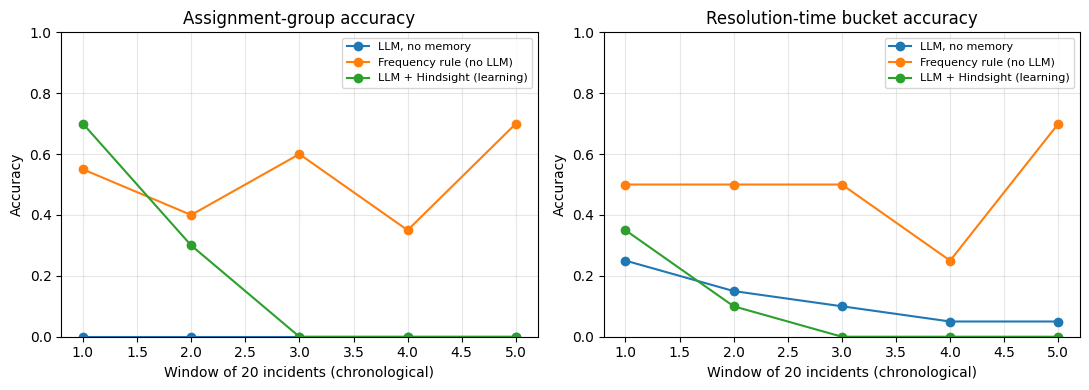

Overall accuracy over 100 live incidents
base_group_ok     0.00
base_bucket_ok    0.12
rule_group_ok     0.52
rule_bucket_ok    0.49
hs_group_ok       0.20
hs_bucket_ok      0.09


,window,baseline_acc,rule_acc,hindsight_acc,baseline_ttr_acc,rule_ttr_acc,hindsight_ttr_acc
0,1,0.0,0.55,0.7,0.25,0.50,0.35
1,2,0.0,0.40,0.3,0.15,0.50,0.10
2,3,0.0,0.60,0.0,0.10,0.50,0.00
3,4,0.0,0.35,0.0,0.05,0.25,0.00
4,5,0.0,0.70,0.0,0.05,0.70,0.00


In [ ]:
res = pd.DataFrame(rows)
for who in ("base", "rule", "hs"):
    res[f"{who}_group_ok"] = res[f"{who}_group"].map(norm) == res.truth_group.map(norm)
    res[f"{who}_bucket_ok"] = res[f"{who}_bucket"].map(norm) == res.truth_bucket.map(norm)
res["window"] = np.arange(len(res)) // WINDOW + 1

win = res.groupby("window").agg(
    baseline_acc=("base_group_ok", "mean"), rule_acc=("rule_group_ok", "mean"), hindsight_acc=("hs_group_ok", "mean"),
    baseline_ttr_acc=("base_bucket_ok", "mean"), rule_ttr_acc=("rule_bucket_ok", "mean"),
    hindsight_ttr_acc=("hs_bucket_ok", "mean")).reset_index()
eval_windows = win
win.to_csv("eval_results.csv", index=False)
res.to_csv("eval_incident_log.csv", index=False)

def make_eval_fig(w):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    panels = [(("baseline_acc", "rule_acc", "hindsight_acc"), "Assignment-group accuracy"),
              (("baseline_ttr_acc", "rule_ttr_acc", "hindsight_ttr_acc"), "Resolution-time bucket accuracy")]
    labels = ["LLM, no memory", "Frequency rule (no LLM)", "LLM + Hindsight (learning)"]
    for ax, (cols, title) in zip(axes, panels):
        for c, label in zip(cols, labels):
            ax.plot(w["window"], w[c], marker="o", label=label)
        ax.set_ylim(0, 1); ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
        ax.set_xlabel(f"Window of {WINDOW} incidents (chronological)"); ax.set_ylabel("Accuracy")
    fig.tight_layout()
    return fig

fig = make_eval_fig(win)
plt.show()
print("Overall accuracy over", len(res), "live incidents")
print(res[[c for c in res.columns if c.endswith("_ok")]].mean().round(3).to_string())
win.round(2)

## Improvement 4: Hindsight `reflect`
`reflect` asks Hindsight to synthesize patterns across everything it retained. Keep the two or three best answers for your slides. The method signature is taken from the Hindsight client docs; if it differs in your installed version the cell prints the error instead of crashing.

In [ ]:
for name, bank, q in [
    ("Curated demo bank", BANK_ID, "What recurring root causes and lessons appear across past incidents?"),
    ("Real-data bank", BANK_V2, "Which categories tend to be reassigned or resolved slowly, and which groups usually resolve them?"),
]:
    print("=" * 70, f"\n{name}\n", "=" * 70)
    try:
        r = hs_client.reflect(bank_id=bank, query=q)
        print(getattr(r, "text", None) or r, "\n")
    except Exception as e:
        print("reflect not available:", e, "\n")

Curated demo bank
Based on the incident records from September 2026, several recurring themes regarding root causes and actionable lessons have been identified. These patterns highlight vulnerabilities in deployment processes, infrastructure configurations, and third-party dependencies.

### Recurring Root Causes
The incidents analyzed reveal a high frequency of technical issues stemming from configuration changes, resource limitations, and dependency management:

*   **Deployment and Configuration Errors:** Many incidents were triggered by recent deployments, including missing environment variables (INC1007), incorrect feature flag rollouts (INC1028), and Kubernetes liveness probe misconfigurations (INC1022).
*   **Resource Exhaustion:** A significant number of incidents involved resource limits being reached, specifically database connection pool exhaustion (INC1002, INC1017), memory leaks in services (INC1001, INC1015), and disk partition saturation due to unrotated logs (INC1006).


# Part 3: Interactive UI (Gradio, runs inside this notebook)
Run the next cell and open the public link it prints (or use the inline view).

- **Live agent** tab: type or click an example incident, watch what Hindsight recalls (the memory the diagnosis used is marked), then use *Resolve and teach* and analyze a similar incident.
- **Evidence** tab: the baseline-vs-Hindsight chart from Improvement 3.

The live tab uses the curated demo bank (`BANK_ID`), so its examples match Steps 8 to 12; the Evidence tab shows the real-data results.

In [ ]:
import asyncio
import uvicorn.server as _uvicorn_server

def _run_compat(coro, **kwargs):
    # newer uvicorn passes loop_factory=..., which nest_asyncio's patched asyncio.run rejects
    loop = asyncio.new_event_loop()
    try:
        asyncio.set_event_loop(loop)
        return loop.run_until_complete(coro)
    finally:
        loop.close()

if hasattr(_uvicorn_server, "asyncio_run"):
    _uvicorn_server.asyncio_run = _run_compat
print("Compatibility patch applied.")

Compatibility patch applied.


In [ ]:
import asyncio, threading
from hindsight_client import Hindsight

HINDSIGHT_URL = "https://api.hindsight.vectorize.io"

# One dedicated event loop, running in its own background thread, for every Hindsight call.
_hs_loop = asyncio.new_event_loop()
threading.Thread(target=_hs_loop.run_forever, daemon=True, name="hindsight-loop").start()

class ThreadSafeHindsight:
    """Same interface as the Hindsight client, but safe to call from any thread (Gradio uses worker threads)."""
    def __init__(self, client, loop):
        self._c, self._loop = client, loop
    def __getattr__(self, name):
        afn = getattr(self._c, "a" + name, None)          # retain -> aretain, recall -> arecall, reflect -> areflect ...
        if callable(afn):
            def call(*args, **kwargs):
                fut = asyncio.run_coroutine_threadsafe(afn(*args, **kwargs), self._loop)
                return fut.result(timeout=180)
            return call
        return getattr(self._c, name)

hs_client = ThreadSafeHindsight(Hindsight(base_url=HINDSIGHT_URL, api_key=hindsight_api_key), _hs_loop)
print("Hindsight client is now thread-safe.")

Hindsight client is now thread-safe.


In [ ]:
import gradio as gr

EXAMPLES = {
    "Auth / 2FA failure": "Users getting logged out randomly and 2FA codes aren't arriving via text message.",
    "Disk full": "Application logs stopped writing, disk usage on the file server shows 100% full.",
    "DNS issue": "Some users can't reach our website at all, getting 'server not found' errors intermittently.",
    "Cache failure": "Website is loading very slowly for everyone, cache hit rate dropped to almost zero.",
    "Payment outage": "Customers can't complete payment, card transactions are all failing.",
    "Kubernetes crash loop": "Pods in the order processing cluster keep restarting over and over.",
    "Mobile crash (teach it this)": "Users report the mobile app freezes and crashes immediately after opening, started right after today's app update.",
    "Printer (unrelated check)": "The office printer on the 3rd floor is out of toner and needs a refill.",
}
ICON = {"Critical": "🔴", "High": "🟠", "Medium": "🟡", "Low": "🟢"}
LEARN_LOG = []

def as_list(x):
    return x if isinstance(x, list) else ([str(x)] if x else [])

def render_diag(r):
    sev = r.get("severity", "?")
    lines = [f"### {r.get('summary', '')}",
             f"**Severity:** {ICON.get(sev, '⚪')} {sev} &nbsp;|&nbsp; **Category:** {r.get('category', '?')} "
             f"&nbsp;|&nbsp; **Confidence:** {str(r.get('confidence', '?')).capitalize()}", "", "**Likely root causes**"]
    lines += [f"- {c}" for c in as_list(r.get("root_causes"))]
    lines += ["", "**Investigation steps**"]
    lines += [f"{i}. {s}" for i, s in enumerate(as_list(r.get("investigation_steps")), 1)]
    lines += ["", f"> **Do now:** {r.get('immediate_action', '')}", f"> **Escalate to:** {r.get('escalation', '')}",
              "", f"*Memory match: {r.get('similar_incident', '')}*"]
    return "\n".join(lines)

def render_mem(matches, cited):
    if not matches:
        return "_Nothing recalled. The agent is reasoning without memory._"
    out = []
    for i, (t, s) in enumerate(matches, 1):
        tag = "✅ **Used in the diagnosis**\n\n" if str(cited) == str(i) else ""
        out.append(f"**Memory {i}**\n\n{tag}> {t[:500]}")
    return "\n\n---\n\n".join(out)

def ui_analyze(text):
    text = (text or "").strip()
    if not text:
        return "Describe an incident first.", "", ""
    try:
        matches = find_similar_hindsight(text, top_k=3)
        r = diagnose_json(text, matches)
    except Exception as e:
        return f"⚠️ Something went wrong: {e}", "", text
    return render_diag(r), render_mem(matches, r.get("cited_memory")), text

def ui_teach(text, cause, action, outcome):
    if not text or not cause.strip() or not action.strip():
        return "Analyze an incident first, then fill in root cause and action.", "\n".join(LEARN_LOG)
    try:
        hs_client.retain(bank_id=BANK_ID, content=(
            f"Incident: {text}\nRoot Cause: {cause}\nAction Taken: {action}\nOutcome: {outcome or 'Resolved'}\n"
            f"Lesson: When incidents like this occur, check for {cause} first."))
    except Exception as e:
        return f"⚠️ Could not save: {e}", "\n".join(LEARN_LOG)
    LEARN_LOG.append(f"- Learned: {cause}")
    return "🧠 Saved. Now analyze a similar incident.", "\n".join(LEARN_LOG)

def ui_reflect():
    try:
        r = hs_client.reflect(bank_id=BANK_ID, query="What recurring root causes and lessons appear across past incidents?")
        return getattr(r, "text", None) or str(r)
    except Exception as e:
        return f"reflect not available: {e}"

def ui_evidence():
    w = globals().get("eval_windows")
    if w is None:
        try:
            w = pd.read_csv("eval_results.csv")
        except Exception:
            return None, pd.DataFrame({"info": ["Run the Improvement 3 cells first."]})
    fig = make_eval_fig(w)
    plt.close(fig)
    return fig, w.round(2)

if "ui" in globals():
    try:
        ui.close()
    except Exception:
        pass

with gr.Blocks(title="Incident Response Agent", theme=gr.themes.Soft()) as ui:
    gr.Markdown("# 🚨 Incident Response Agent\nAn agent that remembers past incidents and gets better with every one it resolves.")
    last_inc = gr.State("")
    with gr.Tabs():
        with gr.Tab("Live agent"):
            with gr.Row():
                with gr.Column(scale=3):
                    inc_box = gr.Textbox(label="Incident description", lines=4, placeholder="Describe what is happening…")
                    analyze_btn = gr.Button("Analyze incident", variant="primary")
                    gr.Examples(examples=[[v] for v in EXAMPLES.values()], inputs=[inc_box], label="Example incidents")
                    diag_out = gr.Markdown()
                with gr.Column(scale=2):
                    gr.Markdown("## 🧠 Agent Memory\nWhat Hindsight recalled for this incident")
                    mem_out = gr.Markdown("_Analyze an incident to see recalled memory here._")
                    with gr.Accordion("Patterns Hindsight has learned (reflect)", open=False):
                        reflect_btn = gr.Button("Generate insights")
                        reflect_out = gr.Markdown()
            gr.Markdown("### Resolve and teach the agent")
            with gr.Row():
                cause_box = gr.Textbox(label="Actual root cause")
                action_box = gr.Textbox(label="Action taken")
                outcome_box = gr.Textbox(label="Outcome", value="Resolved")
            teach_btn = gr.Button("Save to memory")
            teach_msg = gr.Markdown()
            log_out = gr.Markdown()
        with gr.Tab("Evidence"):
            gr.Markdown("### Does memory actually help?\nRolling accuracy on a chronological stream of real incidents.")
            ev_btn = gr.Button("Refresh")
            ev_plot = gr.Plot()
            ev_table = gr.Dataframe()
    analyze_btn.click(ui_analyze, [inc_box], [diag_out, mem_out, last_inc])
    teach_btn.click(ui_teach, [last_inc, cause_box, action_box, outcome_box], [teach_msg, log_out])
    reflect_btn.click(ui_reflect, None, reflect_out)
    ev_btn.click(ui_evidence, None, [ev_plot, ev_table])
    ui.load(ui_evidence, None, [ev_plot, ev_table])

ui.launch(share=True, debug=False)

/tmp/ipykernel_1923/1102668714.py:87: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Incident Response Agent", theme=gr.themes.Soft()) as ui:
ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-1136' coro=<sleep() running at /usr/lib/python3.13/asyncio/tasks.py:720> wait_for=<Future pending cb=[Task.__wakeup()]>>
ERROR:asyncio:Task was destroyed but it is pending!
task: <Task pending name='Task-1137' coro=<sleep() running at /usr/lib/python3.13/asyncio/tasks.py:720> wait_for=<Future pending cb=[Task.__wakeup()]>>


Closing server running on port: 7860
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5e499fac8f501ee9b0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Demo checklist
1. **Live agent tab:** click *Auth / 2FA failure*, Analyze. Point at the Agent Memory panel and the ✅ marker.
2. Click *Mobile crash*, Analyze (weak or no match), then fill *Resolve and teach* and save.
3. Analyze a similar mobile-crash sentence. The agent now recalls the lesson.
4. Click *Printer*. The agent should say there is no related incident instead of inventing one.
5. **Evidence tab:** show the chart and be honest about the frequency-rule line. Explain where memory helps (learning, explanation, novel patterns) and where a lookup table is competitive.

Before presenting: re-run Improvement 3 once with a larger `N_TEST` if time and Groq limits allow, and keep a screen recording as a fallback.